# Gráfico final

## Importações

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from pathlib import Path

from nucleo import (
    euler_exato,
    caracteristica_euler_suave_4,
    caracteristica_euler_suave_8,
    listar_imagens, 
    carregar_imagem,
    TEMPERATURA_PADRAO,
    LIMIAR
)

## Configurações

In [19]:
TEMPERATURAS = [0.01, 0.005, 0.0001]
N_SINTETICAS = 300
PASTA_TILE = Path("datasets/MVTecAD/tile")

## Imagens binárias

In [20]:
aleatorias = (F.avg_pool2d(torch.rand(N_SINTETICAS, 1, 34, 34), 3, 1, 1) > 0.5).float()[:, :, 1:-1, 1:-1]

# Euler exato
exato_sintetico = np.array([euler_exato(m[0].numpy(), conectividade=1) for m in aleatorias])

# Euler suave para cada temperatura
suave_sintetico = {}

with torch.no_grad():
    for T in TEMPERATURAS:
        suave_sintetico[T] = (caracteristica_euler_suave_4(aleatorias, T).cpu().numpy())


## DATASET MVTec AD - TILE

In [26]:
arquivos = listar_imagens(PASTA_TILE / "train" / "good")[:35]
tile = torch.stack([carregar_imagem(a) for a in arquivos])

In [27]:
exato_mvtec = []

suave_mvtec = {T: [] for T in TEMPERATURAS}

with torch.no_grad():
    for inicio in range(0, len(tile), 32):
        alvo = tile[inicio:inicio + 32].cpu()

        # Euler suave
        for T in TEMPERATURAS:
            chi_suave = caracteristica_euler_suave_4(alvo, T).cpu().numpy()

            suave_mvtec[T].extend(chi_suave)

        # Euler exato
        for imagem in alvo:
            imagem_np = imagem[0].numpy()
            imagem_binaria = (imagem_np >= 0.5).astype(np.uint8)

            chi_exato = euler_exato(imagem_binaria, conectividade=1)

            exato_mvtec.append(chi_exato)

exato_mvtec = np.asarray(exato_mvtec)

for T in TEMPERATURAS:
    suave_mvtec[T] = np.asarray(suave_mvtec[T])

## Métricas

In [28]:
def calcular_metricas(exato, suave):

    erro_medio = np.mean(np.abs(suave - exato))
    erro_maximo = np.max(np.abs(suave - exato))
    acerto = np.mean(np.round(suave) == exato) * 100

    return erro_medio, erro_maximo, acerto


metricas_sinteticas = {T: calcular_metricas(exato_sintetico, suave_sintetico[T]) for T in TEMPERATURAS}
metricas_mvtec = {T: calcular_metricas(exato_mvtec, suave_mvtec[T]) for T in TEMPERATURAS}

## Visualização

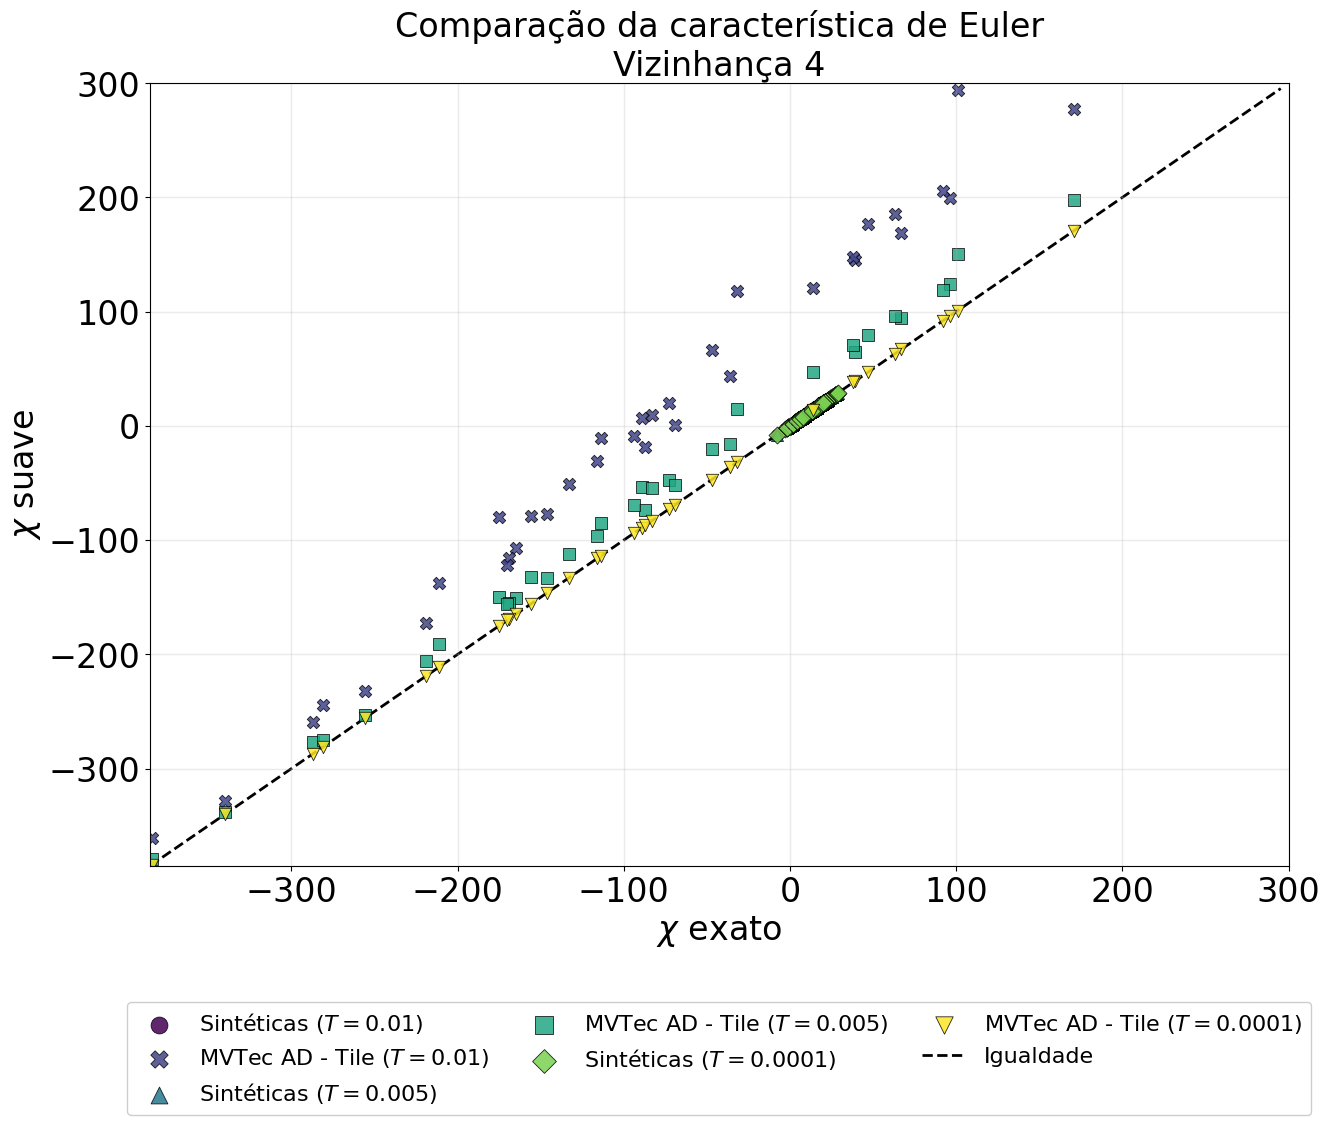

In [36]:
plt.rcParams.update({
    "font.size": 24,
    "axes.labelsize": 24,
    "axes.titlesize": 24,
    "xtick.labelsize": 24,
    "ytick.labelsize": 24,
    "legend.fontsize": 24
})

fig, eixo = plt.subplots(figsize=(14, 12))

# Seis cores bem separadas da paleta viridis
cores = plt.cm.viridis([0.00, 0.20, 0.40, 0.60, 0.80, 1.00])

# Marcadores distintos para cada combinação
marcadores_sinteticas = {
    0.01: "o",       # círculo
    0.005: "^",      # triângulo
    0.0001: "D"      # losango
}

marcadores_mvtec = {
    0.01: "X",       # cruz preenchida
    0.005: "s",      # quadrado
    0.0001: "v"      # triângulo invertido
}

indice_cor = 0

for T in TEMPERATURAS:

    # Imagens binarias sinteticas
    eixo.scatter(
        exato_sintetico,
        suave_sintetico[T],
        s=75,
        alpha=0.85,
        color=cores[indice_cor],
        marker=marcadores_sinteticas[T],
        edgecolors="black",
        linewidths=0.6,
        label=rf"Sintéticas ($T={T}$)"
    )

    indice_cor += 1

    # MVTec AD - Tile
    eixo.scatter(
        exato_mvtec,
        suave_mvtec[T],
        s=80,
        alpha=0.85,
        color=cores[indice_cor],
        marker=marcadores_mvtec[T],
        edgecolors="black",
        linewidths=0.6,
        label=rf"MVTec AD - Tile ($T={T}$)"
    )

    indice_cor += 1

# Reta da igualdade
todos_exatos = np.concatenate([exato_sintetico, exato_mvtec])
todos_suaves = np.concatenate([suave_sintetico[T] for T in TEMPERATURAS] + [suave_mvtec[T] for T in TEMPERATURAS])

minimo = min(todos_exatos.min(), todos_suaves.min()) - 1

maximo = max(todos_exatos.max(), todos_suaves.max()) + 1

eixo.plot(
    [minimo, maximo],
    [minimo, maximo],
    "k--",
    linewidth=2,
    label="Igualdade",
    zorder=0
)

eixo.set_xlabel(r"$\chi$ exato")
eixo.set_ylabel(r"$\chi$ suave")

eixo.set_title("Comparação da característica de Euler\nVizinhança 4")

eixo.grid(alpha=0.25, linewidth=1)

eixo.set_xlim(minimo, 300)
eixo.set_ylim(minimo, 300)

# Legenda abaixo do grafico
eixo.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    fontsize=16,
    ncol=3,
    framealpha=0.95,
    markerscale=1.4,
    columnspacing=1.5
)

plt.tight_layout()

plt.savefig("comparacao_euler_temperaturas.png", dpi=300, bbox_inches="tight", format="png")

plt.show()



## Resultados

In [30]:
for T in TEMPERATURAS:
    print(f"\nTEMPERATURA T = {T}")

    print("\nIMAGENS SINTETICAS")
    print("Quantidade:", len(exato_sintetico))
    print(f"MAE: {metricas_sinteticas[T][0]:.6f}")
    print(f"Erro maximo: {metricas_sinteticas[T][1]:.6f}")
    print(f"Acerto: {metricas_sinteticas[T][2]:.2f}%")

    print("\nMVTec AD - TILE")
    print("Quantidade:", len(exato_mvtec))
    print(f"MAE: {metricas_mvtec[T][0]:.6f}")
    print(f"Erro maximo: {metricas_mvtec[T][1]:.6f}")
    print(f"Acerto: {metricas_mvtec[T][2]:.2f}%")


TEMPERATURA T = 0.01

IMAGENS SINTETICAS
Quantidade: 300
MAE: 0.000000
Erro maximo: 0.000000
Acerto: 100.00%

MVTec AD - TILE
Quantidade: 35
MAE: 84.512109
Erro maximo: 193.317383
Acerto: 0.00%

TEMPERATURA T = 0.005

IMAGENS SINTETICAS
Quantidade: 300
MAE: 0.000000
Erro maximo: 0.000000
Acerto: 100.00%

MVTec AD - TILE
Quantidade: 35
MAE: 22.570006
Erro maximo: 49.377930
Acerto: 0.00%

TEMPERATURA T = 0.0001

IMAGENS SINTETICAS
Quantidade: 300
MAE: 0.000000
Erro maximo: 0.000000
Acerto: 100.00%

MVTec AD - TILE
Quantidade: 35
MAE: 0.000000
Erro maximo: 0.000000
Acerto: 100.00%
